# SMS Spam Detection: Model Interpretation & Threshold

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_recall_curve, precision_score, recall_score, f1_score

pd.set_option("display.max_colwidth", 120)

DATA_PATH = next(p for p in [Path("../data/sms.tsv"), Path("data/sms.tsv"), Path("sms.tsv")] if p.exists())
MODEL_DIR = next((p for p in [Path("../app"), Path("app")] if p.exists()), Path("."))

df = pd.read_csv(DATA_PATH, sep="\t", header=None, names=["label", "message"])
df = df.drop_duplicates().reset_index(drop=True)
df["target"] = (df["label"] == "spam").astype(int)

# same split as notebook 02
X_train, X_test, y_train, y_test = train_test_split(
    df["message"], df["target"], test_size=0.2, random_state=42, stratify=df["target"]
)

model = joblib.load(MODEL_DIR / "spam_model.pkl")
union = model.named_steps["features"]
clf = model.named_steps["clf"]

terms = pd.DataFrame({"feature": union.get_feature_names_out(), "coef": clf.coef_[0]})
terms["type"] = terms["feature"].str.split("__").str[0]
terms["term"] = terms["feature"].str.split("__", n=1).str[1]
print(terms["type"].value_counts().to_dict())

{'char': 20389, 'word': 3082}


## Which features drive the model

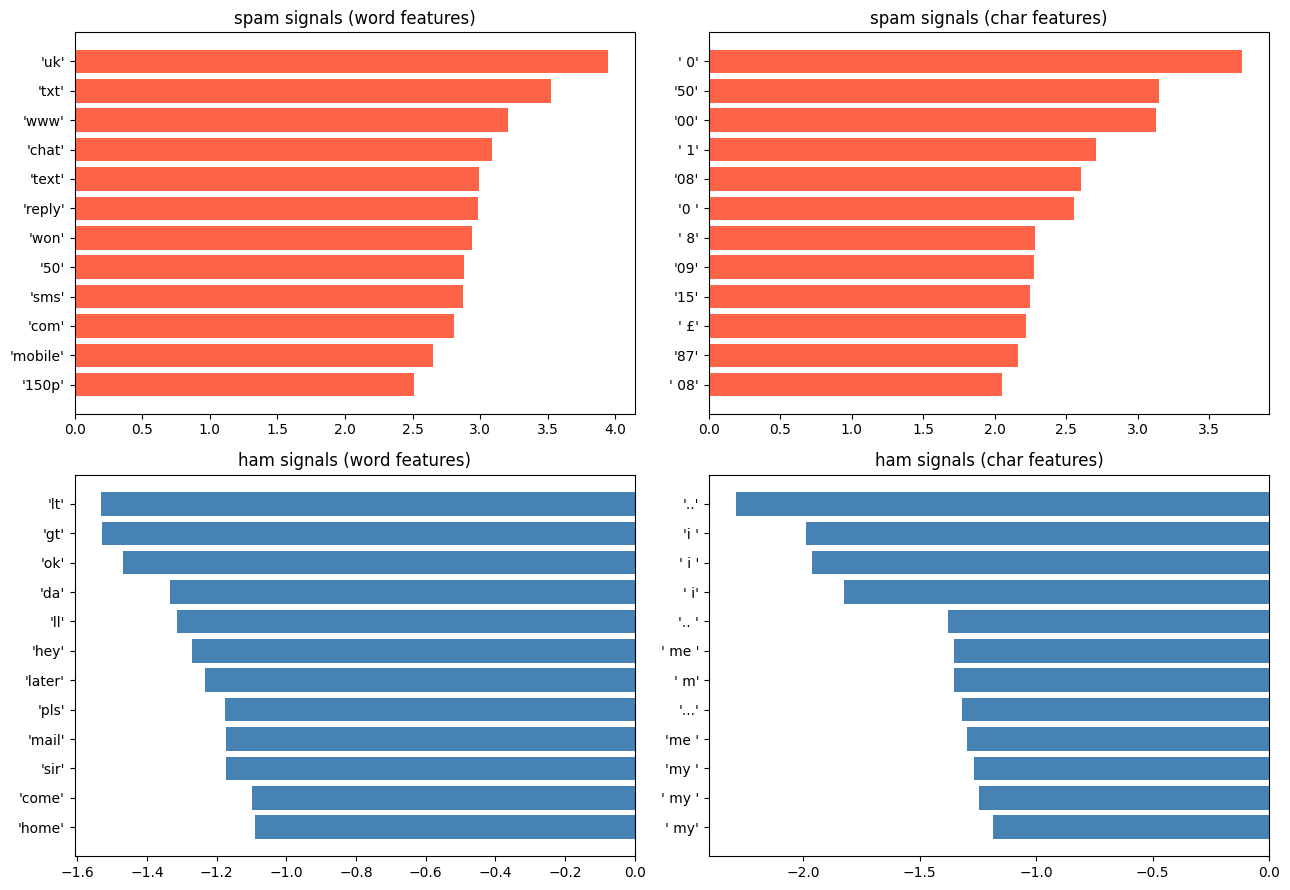

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for row, (direction, color) in enumerate([("spam", "tomato"), ("ham", "steelblue")]):
    for col, kind in enumerate(["word", "char"]):
        subset = terms[terms["type"] == kind]
        top = subset.nlargest(12, "coef") if direction == "spam" else subset.nsmallest(12, "coef")
        axes[row, col].barh(top["term"].map(repr), top["coef"], color=color)
        axes[row, col].set_title(f"{direction} signals ({kind} features)")
        axes[row, col].invert_yaxis()
plt.tight_layout()
plt.show()

## Error analysis at the default 0.5 threshold

In [3]:
proba = model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

errors = pd.DataFrame({"message": X_test.values, "actual": y_test.values, "proba": proba.round(3), "pred": pred})
false_pos = errors[(errors["actual"] == 0) & (errors["pred"] == 1)]
false_neg = errors[(errors["actual"] == 1) & (errors["pred"] == 0)]

print(f"False positives (ham flagged as spam): {len(false_pos)}")
print(f"False negatives (spam missed): {len(false_neg)}")
false_pos

False positives (ham flagged as spam): 6
False negatives (spam missed): 7


,message,actual,proba,pred
29,Your daily text from me – a favour this time,0,0.720,1
293,Are you free now?can i call now?,0,0.564,1
301,"Please protect yourself from e-threats. SIB never asks for sensitive information like Passwords,ATM/SMS PIN thru ema...",0,0.588,1
327,K k:) sms chat with me.,0,0.793,1
749,Glad to see your reply.,0,0.799,1
835,I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to &...,0,0.874,1


In [4]:
false_neg

,message,actual,proba,pred
308,Hi its LUCY Hubby at meetins all day Fri & I will B alone at hotel U fancy cumin over? Pls leave msg 2day 0909972639...,1,0.402,0
437,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about ...,1,0.382,0
486,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Da...",1,0.055,0
690,"Latest News! Police station toilet stolen, cops have nothing to go on!",1,0.256,0
801,Would you like to see my XXX pics they are so hot they were nearly banned in the uk!,1,0.217,0
826,ringtoneking 84484,1,0.159,0
992,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-C...,1,0.395,0


## Choosing a threshold

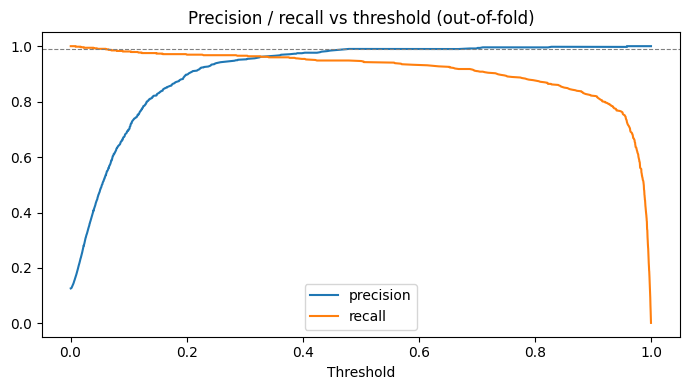

In [5]:
# choose the threshold on out-of-fold training predictions, not on the test set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_proba = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, oof_proba)

plt.figure(figsize=(7, 4))
plt.plot(thresholds, precision[:-1], label="precision")
plt.plot(thresholds, recall[:-1], label="recall")
plt.axhline(0.99, color="gray", linestyle="--", linewidth=0.8)
plt.xlabel("Threshold")
plt.title("Precision / recall vs threshold (out-of-fold)")
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
# flagging a legitimate message as spam is the costly mistake, so require >= 99% precision
# at the chosen threshold and at every higher one (the raw curve is jagged)
TARGET_PRECISION = 0.99
stable_precision = np.minimum.accumulate(precision[:-1][::-1])[::-1]
ok = np.where(stable_precision >= TARGET_PRECISION)[0]
threshold = float(np.ceil(thresholds[ok[0]] * 100) / 100)
print("Chosen threshold:", threshold)

Chosen threshold: 0.69


In [7]:
rows = []
for name, t in [("default 0.50", 0.5), (f"tuned {threshold}", threshold)]:
    p = (proba >= t).astype(int)
    rows.append({
        "setting": name,
        "precision": precision_score(y_test, p),
        "recall": recall_score(y_test, p),
        "f1": f1_score(y_test, p),
        "false_positives": int(((p == 1) & (y_test == 0)).sum()),
        "missed_spam": int(((p == 0) & (y_test == 1)).sum()),
    })

pd.DataFrame(rows).set_index("setting").round(4)

,precision,recall,f1,false_positives,missed_spam
setting,,,,,
default 0.50,0.9538,0.9466,0.9502,6,7
tuned 0.69,0.9675,0.9084,0.9370,4,12


## Explaining a single message

In [8]:
def explain(message, top_n=6):
    row = union.transform([message]).tocoo()
    out = terms.iloc[row.col][["type", "term"]].reset_index(drop=True)
    out["contribution"] = row.data * clf.coef_[0][row.col]

    words = out[out["type"] == "word"]
    top = words.loc[words["contribution"].abs().sort_values(ascending=False).index].head(top_n)
    chars = pd.DataFrame([{"type": "char", "term": "(all character patterns)",
                           "contribution": out.loc[out["type"] == "char", "contribution"].sum()}])
    return pd.concat([top, chars], ignore_index=True)

sample = "WINNER!! You have been selected to receive a £900 prize reward. Call 09061701461 now to claim."
print("Spam probability:", round(model.predict_proba([sample])[0, 1], 3))
explain(sample)

Spam probability: 0.99


,type,term,contribution
0,word,claim,0.674095
1,word,prize,0.547629
2,word,selected,0.224694
3,word,receive,0.211134
4,word,winner,0.204829
5,word,reward,0.181801
6,char,(all character patterns),6.167087


## Save app config

In [9]:
p = (proba >= threshold).astype(int)
config = {
    "threshold": threshold,
    "test_precision": round(precision_score(y_test, p), 4),
    "test_recall": round(recall_score(y_test, p), 4),
    "test_f1": round(f1_score(y_test, p), 4),
}
(MODEL_DIR / "config.json").write_text(json.dumps(config, indent=2))
config

{'threshold': 0.69,
 'test_precision': 0.9675,
 'test_recall': 0.9084,
 'test_f1': 0.937}